# Time series forecasting using Long-Short-Term Memory (LSTM)<br>
Using a Long-Short-Term-Memory (LSTM) algorithm, it is possible to identify complex patterns within a sequence of data and make a time series analysis. The goal is to check if a sea ice extent of Barents-Kara seas can be predicted using a training on its own time series.
The training is done on 80% of the data and the trained model is used to predict the same time series and then, the missing 20% is used to check the performance of the model. A forecast of the time series beyond the testing data is made on the single variable time series.<br>


In [18]:
import numpy as np
import xarray as xr
import matplotlib.pyplot as plt
import xeofs as xe
import cartopy.crs as ccrs
import cartopy.feature as cfeature
import pandas as pd
import scipy


from sklearn.preprocessing import MinMaxScaler

from sklearn.model_selection import train_test_split
from sklearn.metrics import mean_squared_error
from sklearn.metrics import mean_absolute_error
from sklearn.metrics import root_mean_squared_error
from sklearn.metrics import mean_absolute_percentage_error

In [19]:
import tensorflow
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import LSTM, Dense
from sklearn.preprocessing import MinMaxScaler

In [ ]:
# Load the dataset (1 column of dates and one for the values)
data = pd.read_csv("data_dates.csv") #data from ERA5, anomalies on 1980-2024 climatology of sea ice extent standardized on the whole area 68-85°N - 5-90°E

# Convert the 'Month' column to datetime format
data['date'] = pd.to_datetime(data['date'])

# Set 'Month' column as the index
data.set_index('date', inplace=True)

data.head() #to check

,index
date,
1980-01-01,-0.024999
1980-02-01,-0.012897
1980-03-01,-0.347249
1980-04-01,-0.656078
1980-11-01,1.020248


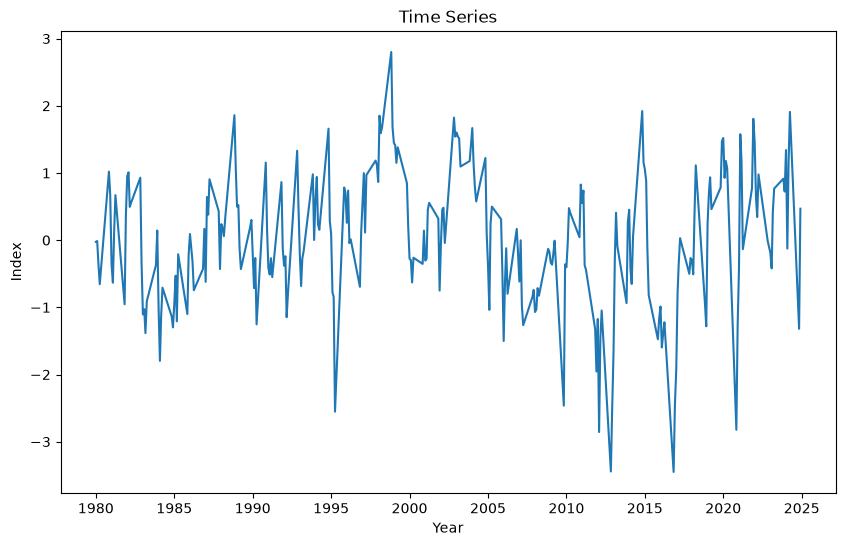

In [21]:
#Plot the time series data
plt.figure(figsize=(10, 6))
plt.plot(data)
plt.title('Time Series')
plt.xlabel('Year')
plt.ylabel('Index')
plt.show()

Epoch 1/200


c:\Users\icyph\climate\Lib\site-packages\keras\src\layers\rnn\rnn.py:199: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(**kwargs)


4/4 ━━━━━━━━━━━━━━━━━━━━ 5s 31ms/step - loss: 0.2642
Epoch 2/200
4/4 ━━━━━━━━━━━━━━━━━━━━ 0s 31ms/step - loss: 0.0563
Epoch 3/200
4/4 ━━━━━━━━━━━━━━━━━━━━ 0s 31ms/step - loss: 0.0338
Epoch 4/200
4/4 ━━━━━━━━━━━━━━━━━━━━ 0s 31ms/step - loss: 0.0311
Epoch 5/200
4/4 ━━━━━━━━━━━━━━━━━━━━ 0s 35ms/step - loss: 0.0273
Epoch 6/200
4/4 ━━━━━━━━━━━━━━━━━━━━ 0s 32ms/step - loss: 0.0235
Epoch 7/200
4/4 ━━━━━━━━━━━━━━━━━━━━ 0s 30ms/step - loss: 0.0250
Epoch 8/200
4/4 ━━━━━━━━━━━━━━━━━━━━ 0s 31ms/step - loss: 0.0227
Epoch 9/200
4/4 ━━━━━━━━━━━━━━━━━━━━ 0s 31ms/step - loss: 0.0233
Epoch 10/200
4/4 ━━━━━━━━━━━━━━━━━━━━ 0s 31ms/step - loss: 0.0228
Epoch 11/200
4/4 ━━━━━━━━━━━━━━━━━━━━ 0s 32ms/step - loss: 0.0227
Epoch 12/200
4/4 ━━━━━━━━━━━━━━━━━━━━ 0s 32ms/step - loss: 0.0229
Epoch 13/200
4/4 ━━━━━━━━━━━━━━━━━━━━ 0s 35ms/step - loss: 0.0226
Epoch 14/200
4/4 ━━━━━━━━━━━━━━━━━━━━ 0s 31ms/step - loss: 0.0226
Epoch 15/200
4/4 ━━━━━━━━━━━━━━━━━━━━ 0s 34ms/step - loss: 0.0226
Epoch 16/200
4/4 ━━━━━━━━━━━━━━

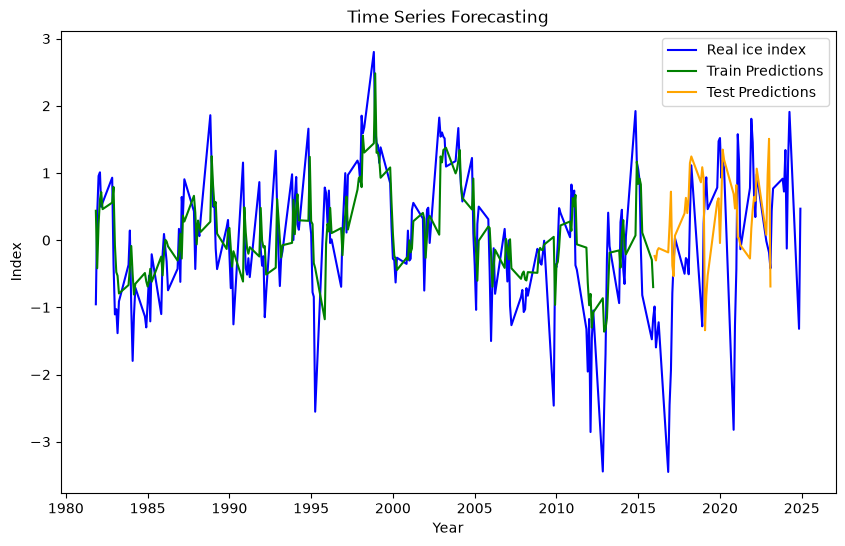

In [22]:
# Normalize the data
scaler = MinMaxScaler()
scaled_data = scaler.fit_transform(data)

# Split the data into train and test sets
train_size = int(len(scaled_data) * 0.8)
train_data = scaled_data[:train_size]
test_data = scaled_data[train_size:]

def create_sequences(data, seq_length):
    X, y = [], []
    for i in range(len(data) - seq_length):
        X.append(data[i:i+seq_length])
        y.append(data[i+seq_length])
    return np.array(X), np.array(y)

seq_length = 10  # Number of time steps to look back and create sequences
X_train, y_train = create_sequences(train_data, seq_length)
X_test, y_test = create_sequences(test_data, seq_length)

#parameterize the model
model = Sequential([
    LSTM(150 , activation='elu', return_sequences=True, input_shape=(seq_length, 1),dropout=(0.00005)),
    LSTM(150 , activation='elu', return_sequences=True, input_shape=(seq_length, 1),dropout=(0.00005)),
    LSTM(150 , activation='elu', return_sequences=True, input_shape=(seq_length, 1),dropout=(0.00005)),
    LSTM(150 , activation='elu', return_sequences=True, input_shape=(seq_length, 1),dropout=(0.00005)),
    LSTM(units=150, activation='elu',dropout=(0.00005)),
    Dense(1, activation='elu')
])

#compile and train data
model.compile(optimizer='adam', loss='mse')
model.fit(X_train, y_train, epochs=200, batch_size=64, verbose=1)

# Make predictions
train_predictions = model.predict(X_train)
test_predictions = model.predict(X_test)

# Inverse transform the predictions
train_predictions = scaler.inverse_transform(train_predictions)
test_predictions = scaler.inverse_transform(test_predictions)

# Plot predictions
plt.figure(figsize=(10, 6))

# Plot actual data
plt.plot(data.index[seq_length:], data['index'][seq_length:], label='Real ice index', color='blue')

# Plot training predictions
plt.plot(data.index[seq_length:seq_length+len(train_predictions)], train_predictions, label='Train Predictions',color='green')

# Plot testing predictions
test_pred_index = range(seq_length+len(train_predictions), seq_length+len(train_predictions)+len(test_predictions))
plt.plot(data.index[test_pred_index], test_predictions, label='Test Predictions',color='orange')

plt.title('Time Series Forecasting')
plt.xlabel('Year')
plt.ylabel('Index')
plt.legend()
plt.show()

## Extract of the thesis : DISCUSSION<br>
The blue plot shows the real standardized value for the sea-ice anomaly index for the Barents-Kara seas. The green plot is the prediction of the model using the data of the training and the reconstruction of the same plot. The plot in orange is the use of the test data with the prediction of the model. The plot on the right is a realignment of the test data (Real value) and the values of the prediction of the model are in orange (Predicted). To determine how accurate are the prediction, the calculation of the root mean square error is done and give the RMSE=0.43 and so the uncertainty.
With the use of the moving time series for forecasting the sea ice index beyond the data, the results give a graph that converge to the mean value at around 0 for both Barents-Kara seas and Greenland ice indices. That trend can be explained by the lack of accuracy of the model to predict values and in that case, deep-learning models have the characteristics to converge to the mean value, as seen here.<br>

The deep learning networks have several limitations due to their internal architecture. One major issue concerns the opacity of the choices of values and the reasoning behind this choice is not accessible, making optimisation and better tuning of this specific parameter not possible. The data have also to be chosen wisely with a precise check to train the model reliably to avoid unproper set-up. The model analyses only statistical regularities among data and doesn’t understand causality or relationship between variables (Tsimenidis 2020). It only predicts based on statistical cycles and don’t really understand the physical meaning of the variables and the phenomena behind them. The network is not aware of what this information really means and lack the abstraction of ontological inference (Tsimenidis 2020).<br>
With these characteristics in mind, it is then difficult to identify the reason why the model cannot predict values after the validation data set. Indeed, several reasons can explain the convergence to the mean. It is the natural tendency of deep learning models, based on the statistics where the decision is not sure to choose a value converging towards the mean. The interpretability is made difficult because of the “black box” behaviour of the model and the hyperparameters fine tuning is really difficult without a really precise knowledge of the internal structure of the network.<br>
The use of deep learning in this approach could not be the better tool in that type of forecasting but the use of neural networks in climate modelling can be a really helpful way to enhance accuracy in addition to more traditional climate models. The development of a hybrid approach with several types of learning method with a method specialised in spatial patterns like self-organising map or convolutional neural network and a method specialised in time series analyses like LSTM or Gradient Recurrent Units could give better results. Several models are available and have proven their usefulness (Amnuaylojaroen 2025, Chen and Dong 2025). The study by Ahanda et al in 2025 shows different results than here with an effective SARIMAX but the Non linear Neural AutoRegressive network predicts also a stabilisation due to more errors. The only remaining question is which one to use depending on the applications and how to train and set up properly.<br>


## REFERENCES<br>
NB:the code is adapted from several forums including the web site "geeks for geeks" and "statology"; the text is an extract of the thesis "From patterns to anomalies: Arctic Oscillations and North Atlantic Oscillations covariability under climate change"<br>
- Ahanda, Yolcu, Watson (2025): “Forecasting arctic sea ice extent trend using time series models: NNAR, SARIMA and SARIMAX using the data prior to the COVID 19 pandemic” https://doi.org/10.1007/s44288-025-00113-w<br>
- Amnuaylojaroen (2025): “Advancements and challenges of artificial intelligence in climate modelling for sustainable urban planning” Front. Artif. Intell. 8:1517986. doi :10.3389/frai.2025.1517986<br>
- Chen and Dong (2025): “Deep learning approaches for time series prediction in climate resilience applications.” Front. Environ. Sci. 13:1574981. doi: 10.3389/fenvs.2025.1574981<br>
- Tsimenidis (2020): “Limitations of Deep Neural Networks: a discussion of G. Marcus' critical appraisal of deep learning” DOI:10.48550/arXiv.2012.15754<br>